# Análise Comparativa e Estatística dos Dados de RF: HFSS vs. Tidy3D vs. Modelo Analítico

Este notebook consolida e analisa estatisticamente os dados simulados no **HFSS** e **Tidy3D** em comparação com os modelos **Analíticos** para 5 topologias de circuitos de micro-ondas em dois conjuntos dielétricos:

1. **Branch-Line** — Frequência de ressonância de $S_{11}$ (GHz)
2. **Cavidade Ressonante** — Frequência do modo fundamental $\text{TE}_{101}$ (GHz) *(Ar $\varepsilon_r = 1{,}0$ e Rutila $\varepsilon_r = 82{,}0$)*
3. **Antena Patch de Microfita** — Frequência de ressonância de $S_{11}$ (GHz)
4. **Divisor de Wilkinson** — Frequência de casamento de $S_{11}$ (GHz)
5. **Linha de Transmissão (Microfita)** — Frequência de ressonância elétrica $\lambda_g/2$ de $S_{12}$ (GHz)

---

### Destaques Metodológicos e Rigor Estatístico (Aulas 5, 6 e 11 dos Slides)
- **Padronização na Mesma Notação (GHz):** Todos os 5 circuitos são medidos na escala de frequência (GHz), eliminando distorções de magnitude.
- **Modelo Analítico como Referência Basal ($y = 0\%$):** A variável resposta da ANOVA é o desvio relativo percentual:
  $$y_{ijk} = \frac{f_{\text{num}, ijk} - f_{\text{analitico}, jk}}{f_{\text{analitico}, jk}} \times 100\%$$
- **ANOVA Fatorial $2 \times 5$ ($N = 20$):** Fator A (Solucionador Numérico: HFSS vs. Tidy3D, $a = 2$), Fator B (Circuito, $b = 5$), e $n = 2$ réplicas dielétricas (FR-4 e RO3010).
- **Validação das Premissas da ANOVA:** Normalidade dos resíduos (Shapiro-Wilk, Q-Q Plot), Homocedasticidade (Teste de Levene, Resíduos vs. Ajustados), e Independência (Durbin-Watson, Resíduos vs. Ordem).
- **Teste de Hipóteses vs. Analítico:** Teste $t$ de Student de uma amostra contra $\mu_0 = 0\%$ e Intervalos de Confiança de 95% para avaliar viés em relação ao modelo analítico.


In [73]:
import os
os.environ["MPLCONFIGDIR"] = os.path.join(os.environ.get("TEMP", "/tmp"), "matplotlib")
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

plt.rcParams["figure.dpi"] = 120
sns.set_theme(style="whitegrid")

# Diretórios de dados (relativos ao notebook)
DIR_FR4 = Path("FR4/Dados")
DIR_RO3010 = Path("RO3010/Dados")

try:
    from IPython.display import display
except Exception:
    display = print


In [74]:
def freq_ressonancia_s11(pasta: Path, arquivo: str, branchline_analitico: bool = False) -> float:
    """Retorna a frequência (GHz) correspondente ao mínimo de S11 (dB)."""
    caminho = pasta / arquivo
    if branchline_analitico:
        cols = ["Freq_GHz", "S11_dB", "S21_dB", "S31_dB", "S41_dB", "Fase_S21", "Fase_S31", "Delta_Fase"]
        df = pd.read_csv(caminho, sep="\t", comment="#", names=cols)
    else:
        df = pd.read_csv(caminho, sep="\t")
    idx_min = df["S11_dB"].idxmin()
    return float(df.loc[idx_min, "Freq_GHz"])


def freq_cavidade_te101(pasta: Path, arquivo: str, col_modo: str, col_freq: str) -> float:
    """Retorna a frequência (GHz) do modo TE_101 na tabela de modos da cavidade."""
    df = pd.read_csv(pasta / arquivo, sep="\t")
    val = df.loc[df[col_modo] == "TE_101", col_freq].iloc[0]
    return float(val)


def freq_linha_transmissao(pasta: Path, arquivo: str) -> float:
    """Retorna a frequência de ressonância lambda/2 (GHz) onde a fase de S12 cruza -180 graus."""
    df = pd.read_csv(pasta / arquivo, sep="\t")
    phase = np.unwrap(np.deg2rad(df["Fase_S12_deg"]))
    target = -np.pi
    idx = np.argmin(np.abs(phase - target))
    f1, f2 = df["Freq_GHz"].iloc[idx - 1], df["Freq_GHz"].iloc[idx]
    p1, p2 = phase[idx - 1], phase[idx]
    f_interp = f1 + (target - p1) * (f2 - f1) / (p2 - p1)
    return float(f_interp)


def montar_matriz_substrato(pasta: Path, sufixo_sub: str, sufixo_cav: str) -> pd.DataFrame:
    dados = {
        "HFSS": [
            freq_ressonancia_s11(pasta, "branchline_3ghz_curvas_hfss.txt"),
            freq_cavidade_te101(pasta, "cavidade_modos_20_hfss.txt", "Modo_Teorico", "Freq_GHz_HFSS"),
            freq_ressonancia_s11(pasta, "patch_3ghz_curvas_hfss.txt"),
            freq_ressonancia_s11(pasta, "wilkinson_3ghz_curvas_hfss.txt"),
            freq_linha_transmissao(pasta, "linha_microfita_curvas_hfss.txt"),
        ],
        "Tidy3D": [
            freq_ressonancia_s11(pasta, "branchline_3ghz_curvas_tidy3d.txt"),
            freq_cavidade_te101(pasta, "cavidade_modos_20_tidy3d.txt", "Modo_Teorico", "Freq_GHz_Tidy3D"),
            freq_ressonancia_s11(pasta, "patch_3ghz_curvas_tidy3d.txt"),
            freq_ressonancia_s11(pasta, "wilkinson_3ghz_curvas_tidy3d.txt"),
            freq_linha_transmissao(pasta, "linha_microfita_curvas_tidy3d.txt"),
        ],
        "Analítico": [
            freq_ressonancia_s11(pasta, "branchline_3ghz_curvas.txt", branchline_analitico=True),
            freq_cavidade_te101(pasta, "cavidade_modos_30.txt", "Modo", "Freq_GHz"),
            freq_ressonancia_s11(pasta, "patch_3ghz_curvas.txt"),
            freq_ressonancia_s11(pasta, "wilkinson_3ghz_curvas.txt"),
            freq_linha_transmissao(pasta, "linha_microfita_curvas.txt"),
        ],
    }
    modelos = [
        f"Branch-Line [{sufixo_sub}] (f_res S11) [GHz]",
        f"Cavidade [{sufixo_cav}] (TE_101) [GHz]",
        f"Antena Patch [{sufixo_sub}] (f_res S11) [GHz]",
        f"Divisor Wilkinson [{sufixo_sub}] (f_res S11) [GHz]",
        f"Linha de Transmissão [{sufixo_sub}] (f_res S12) [GHz]",
    ]
    return pd.DataFrame(dados, index=modelos)


df_fr4 = montar_matriz_substrato(DIR_FR4, "FR-4", "Ar")
df_ro3010 = montar_matriz_substrato(DIR_RO3010, "RO3010", "Rutila")
df_todos = pd.concat([df_fr4, df_ro3010])

print("=== Matriz 1: FR-4 / Ar (5×3 = 15 elementos, todos em GHz) ===")
display(df_fr4.round(4))

print("\n=== Matriz 2: Rogers RO3010 / Rutila (5×3 = 15 elementos, todos em GHz) ===")
display(df_ro3010.round(4))

print("\n=== Matriz Consolidada: Todos os Modelos (10×3 = 30 elementos, todos em GHz) ===")
display(df_todos.round(4))

# Criação do DataFrame tabular no formato longo (long format) para a modelagem estatística
circuitos_nomes = ["Branch-Line", "Cavidade", "Antena Patch", "Divisor Wilkinson", "Linha Transmissao"]
linhas_long = []

for conj, repl, sub_die, df_sub in [
    ("FR4", 1, ["FR-4 (er=4.4)", "Ar (er=1.0)", "FR-4 (er=4.4)", "FR-4 (er=4.4)", "FR-4 (er=4.4)"], df_fr4),
    ("RO3010", 2, ["RO3010 (er=10.2)", "Rutila (er=82.0)", "RO3010 (er=10.2)", "RO3010 (er=10.2)", "RO3010 (er=10.2)"], df_ro3010),
]:
    for idx_circ, circ in enumerate(circuitos_nomes):
        ref = df_sub.iloc[idx_circ]["Analítico"]
        diel = sub_die[idx_circ]
        for met in ["HFSS", "Tidy3D", "Analitico"]:
            val = df_sub.iloc[idx_circ]["Analítico" if met == "Analitico" else met]
            y_n = (val - ref) / ref
            err_pct = y_n * 100.0
            linhas_long.append({
                "Conjunto": conj,
                "Replica": repl,
                "Circuito": circ,
                "Dieletrico": diel,
                "Unidade": "GHz",
                "Metodo": met,
                "Valor": float(val),
                "Ref_Analitico": float(ref),
                "y_norm": float(y_n),
                "Erro_Pct": float(err_pct),
            })

df_rf_long = pd.DataFrame(linhas_long)

# Salvar dados consolidados no arquivo central de dados
caminho_dados_consolidados = Path("../dados_rf_consolidados.txt")
if not caminho_dados_consolidados.parent.exists():
    caminho_dados_consolidados = Path("dados_rf_consolidados.txt")
df_rf_long.to_csv(caminho_dados_consolidados, sep="\t", index=False, float_format="%.6f")
print(f"\nBase de dados consolidada salva em: {caminho_dados_consolidados.resolve()} ({len(df_rf_long)} registros)")


=== Matriz 1: FR-4 / Ar (5×3 = 15 elementos, todos em GHz) ===


,HFSS,Tidy3D,Analítico
Branch-Line [FR-4] (f_res S11) [GHz],2.9737,3.3163,3.0000
Cavidade [Ar] (TE_101) [GHz],3.6844,3.6855,3.6842
Antena Patch [FR-4] (f_res S11) [GHz],2.9122,2.9531,3.0000
Divisor Wilkinson [FR-4] (f_res S11) [GHz],2.5013,2.5775,3.0000
Linha de Transmissão [FR-4] (f_res S12) [GHz],1.5910,1.5963,1.6438



=== Matriz 2: Rogers RO3010 / Rutila (5×3 = 15 elementos, todos em GHz) ===


,HFSS,Tidy3D,Analítico
Branch-Line [RO3010] (f_res S11) [GHz],3.2075,3.1825,3.0000
Cavidade [Rutila] (TE_101) [GHz],3.6844,3.6840,3.6842
Antena Patch [RO3010] (f_res S11) [GHz],2.9415,2.9333,3.0000
Divisor Wilkinson [RO3010] (f_res S11) [GHz],2.0587,2.1275,3.0000
Linha de Transmissão [RO3010] (f_res S12) [GHz],1.1484,1.1273,1.1483



=== Matriz Consolidada: Todos os Modelos (10×3 = 30 elementos, todos em GHz) ===


,HFSS,Tidy3D,Analítico
Branch-Line [FR-4] (f_res S11) [GHz],2.9737,3.3163,3.0000
Cavidade [Ar] (TE_101) [GHz],3.6844,3.6855,3.6842
Antena Patch [FR-4] (f_res S11) [GHz],2.9122,2.9531,3.0000
Divisor Wilkinson [FR-4] (f_res S11) [GHz],2.5013,2.5775,3.0000
Linha de Transmissão [FR-4] (f_res S12) [GHz],1.5910,1.5963,1.6438
Branch-Line [RO3010] (f_res S11) [GHz],3.2075,3.1825,3.0000
Cavidade [Rutila] (TE_101) [GHz],3.6844,3.6840,3.6842
Antena Patch [RO3010] (f_res S11) [GHz],2.9415,2.9333,3.0000
Divisor Wilkinson [RO3010] (f_res S11) [GHz],2.0587,2.1275,3.0000
Linha de Transmissão [RO3010] (f_res S12) [GHz],1.1484,1.1273,1.1483



Base de dados consolidada salva em: C:\Users\filip\Desktop\Github\Projetos---Planejamento-e-Analise-de-Experimentos\Trabalho Final\dados_rf_consolidados.txt (30 registros)


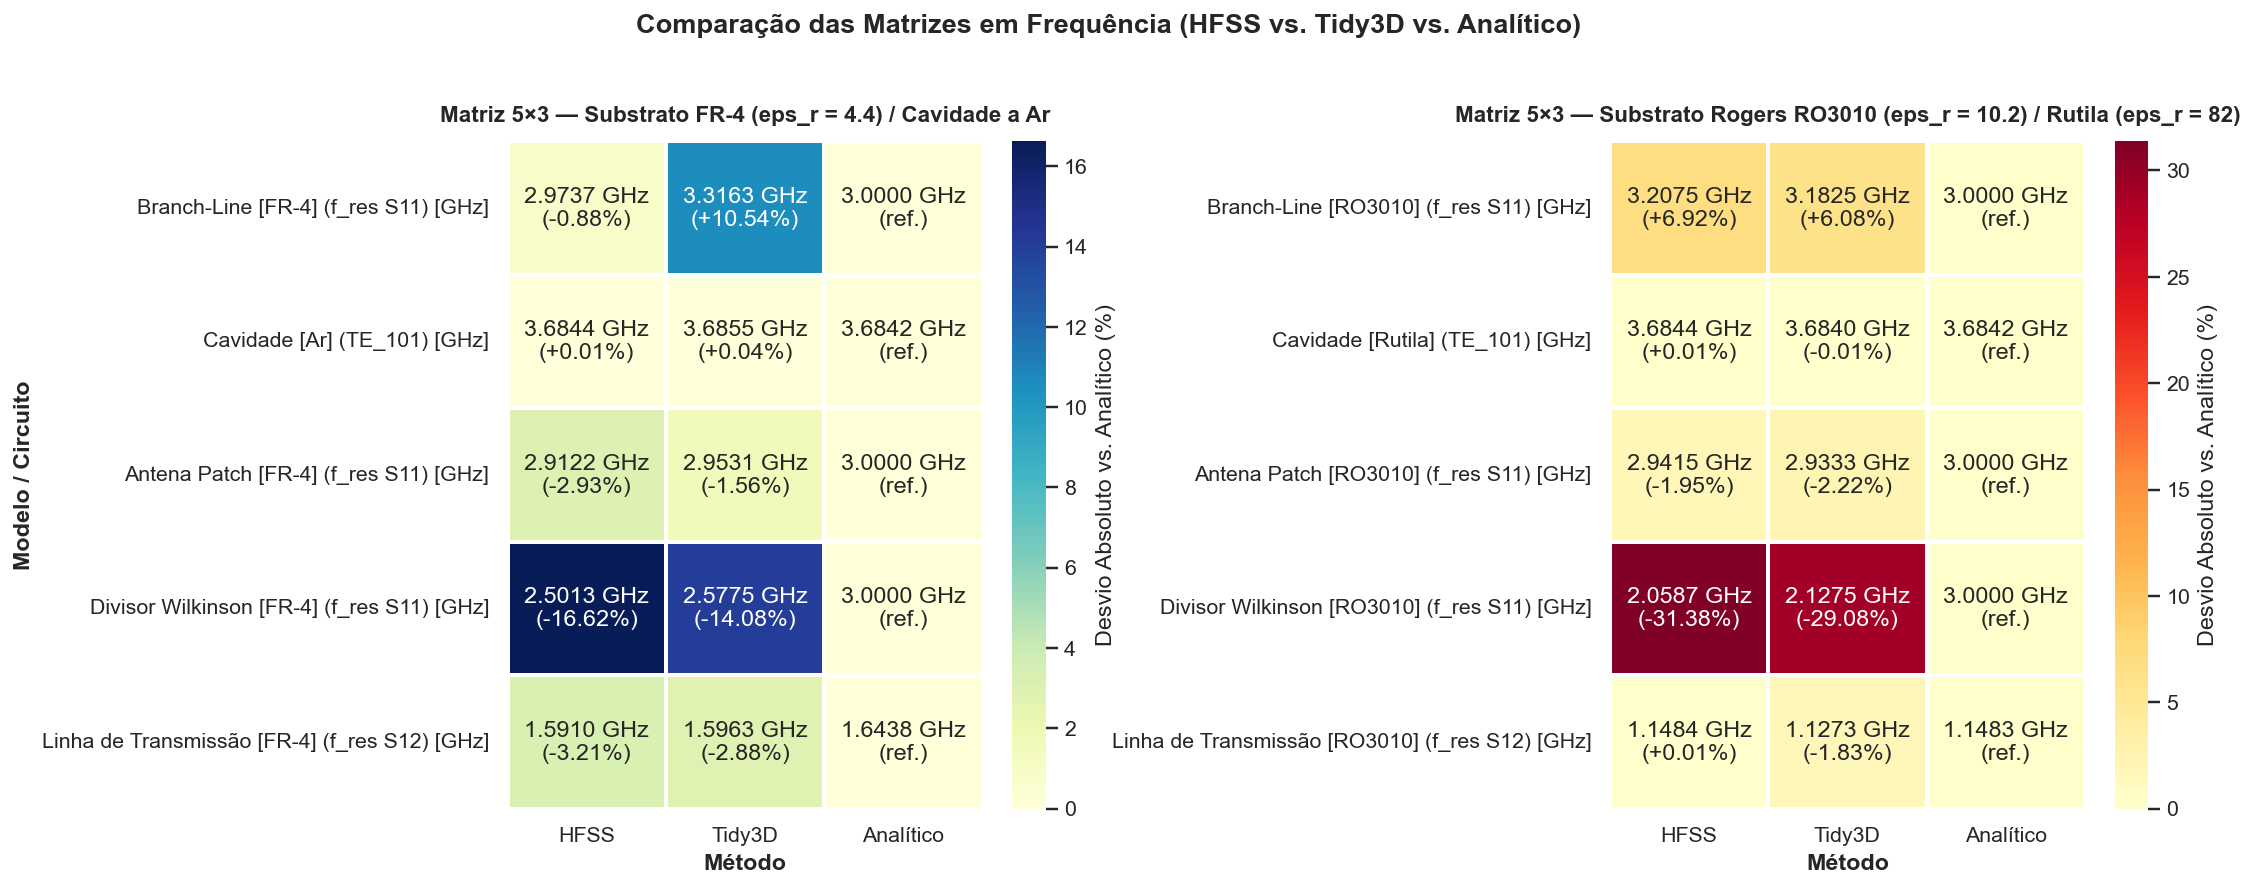

In [75]:
def gerar_anotacoes_e_desvio(df: pd.DataFrame):
    df_desvio = df.sub(df["Analítico"], axis=0).div(df["Analítico"].abs(), axis=0) * 100.0
    anot = np.empty(df.shape, dtype=object)
    for i in range(df.shape[0]):
        for j in range(df.shape[1]):
            val = df.iloc[i, j]
            if j < 2:
                diff = df_desvio.iloc[i, j]
                anot[i, j] = f"{val:.4f} GHz\n({diff:+.2f}%)"
            else:
                anot[i, j] = f"{val:.4f} GHz\n(ref.)"
    return df_desvio, anot


desv_fr4, anot_fr4 = gerar_anotacoes_e_desvio(df_fr4)
desv_ro, anot_ro = gerar_anotacoes_e_desvio(df_ro3010)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6.2), dpi=140)

sns.heatmap(
    desv_fr4.abs(),
    annot=anot_fr4,
    fmt="",
    cmap="YlGnBu",
    linewidths=1.2,
    linecolor="white",
    cbar_kws={"label": "Desvio Absoluto vs. Analítico (%)"},
    ax=ax1,
)
# Uso de string segura para titulos com simbolos matematicos
ax1.set_title("Matriz 5×3 — Substrato FR-4 (eps_r = 4.4) / Cavidade a Ar", fontsize=11.5, fontweight="bold", pad=10)
ax1.set_xlabel("Método", fontweight="bold")
ax1.set_ylabel("Modelo / Circuito", fontweight="bold")
ax1.tick_params(axis="y", rotation=0)

sns.heatmap(
    desv_ro.abs(),
    annot=anot_ro,
    fmt="",
    cmap="YlOrRd",
    linewidths=1.2,
    linecolor="white",
    cbar_kws={"label": "Desvio Absoluto vs. Analítico (%)"},
    ax=ax2,
)
ax2.set_title("Matriz 5×3 — Substrato Rogers RO3010 (eps_r = 10.2) / Rutila (eps_r = 82)", fontsize=11.5, fontweight="bold", pad=10)
ax2.set_xlabel("Método", fontweight="bold")
ax2.set_ylabel("")
ax2.tick_params(axis="y", rotation=0)

plt.suptitle("Comparação das Matrizes em Frequência (HFSS vs. Tidy3D vs. Analítico)", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()


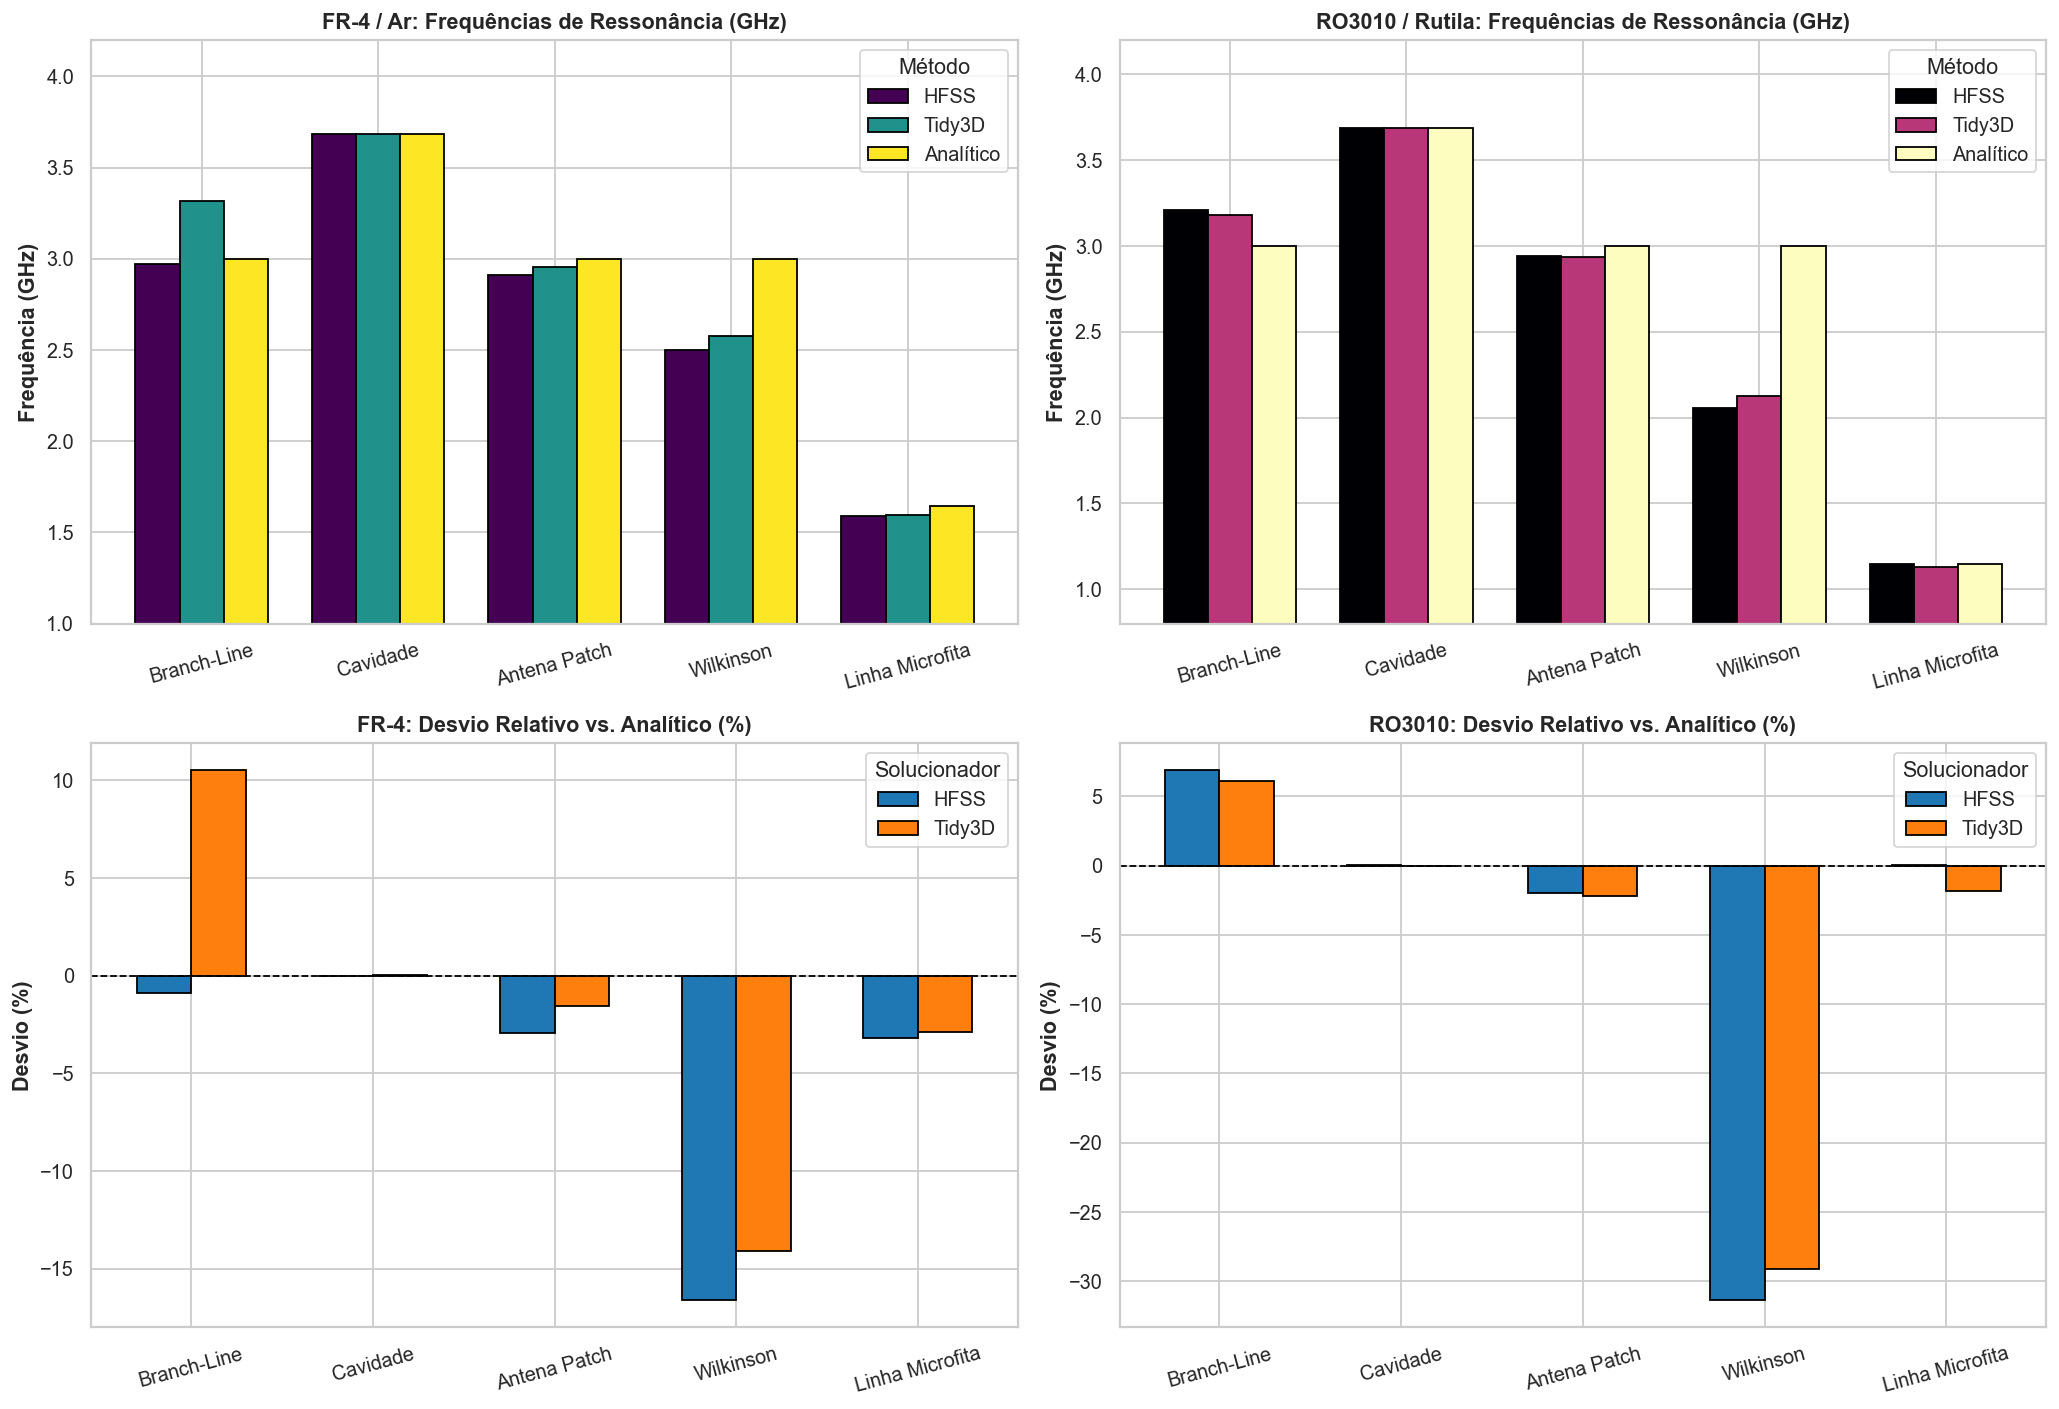

In [76]:
# Painel Comparativo em Barras: Valores Absolutos e Erros Percentuais
fig, axes = plt.subplots(2, 2, figsize=(16, 11), dpi=130)
labels_circ = ["Branch-Line", "Cavidade", "Antena Patch", "Wilkinson", "Linha Microfita"]

# 1. FR-4 / Ar: Frequências Absolutas (5 circuitos em GHz)
df_fr4.plot(kind="bar", ax=axes[0, 0], colormap="viridis", width=0.75, edgecolor="black")
axes[0, 0].set_title("FR-4 / Ar: Frequências de Ressonância (GHz)", fontweight="bold")
axes[0, 0].set_ylabel("Frequência (GHz)", fontweight="bold")
axes[0, 0].set_xticklabels(labels_circ, rotation=15)
axes[0, 0].legend(title="Método")
axes[0, 0].set_ylim(1.0, 4.2)

# 2. RO3010 / Rutila: Frequências Absolutas (5 circuitos em GHz)
df_ro3010.plot(kind="bar", ax=axes[0, 1], colormap="magma", width=0.75, edgecolor="black")
axes[0, 1].set_title("RO3010 / Rutila: Frequências de Ressonância (GHz)", fontweight="bold")
axes[0, 1].set_ylabel("Frequência (GHz)", fontweight="bold")
axes[0, 1].set_xticklabels(labels_circ, rotation=15)
axes[0, 1].legend(title="Método")
axes[0, 1].set_ylim(0.8, 4.2)

# 3. FR-4: Desvio Relativo Percentual (%)
desv_fr4[["HFSS", "Tidy3D"]].plot(kind="bar", ax=axes[1, 0], color=["#1f77b4", "#ff7f0e"], width=0.6, edgecolor="black")
axes[1, 0].axhline(0, color="black", linestyle="--", linewidth=1)
axes[1, 0].set_title("FR-4: Desvio Relativo vs. Analítico (%)", fontweight="bold")
axes[1, 0].set_ylabel("Desvio (%)", fontweight="bold")
axes[1, 0].set_xticklabels(labels_circ, rotation=15)
axes[1, 0].legend(title="Solucionador")

# 4. RO3010: Desvio Relativo Percentual (%)
desv_ro[["HFSS", "Tidy3D"]].plot(kind="bar", ax=axes[1, 1], color=["#1f77b4", "#ff7f0e"], width=0.6, edgecolor="black")
axes[1, 1].axhline(0, color="black", linestyle="--", linewidth=1)
axes[1, 1].set_title("RO3010: Desvio Relativo vs. Analítico (%)", fontweight="bold")
axes[1, 1].set_ylabel("Desvio (%)", fontweight="bold")
axes[1, 1].set_xticklabels(labels_circ, rotation=15)
axes[1, 1].legend(title="Solucionador")

plt.tight_layout()
plt.show()


In [77]:
# =========================================================================
# MODELAGEM ESTATÍSTICA: ANOVA FATORIAL 2 x 5 COM ANALÍTICO COMO REFERÊNCIA
# =========================================================================
# Amostra: N = 20 observações (10 do HFSS e 10 do Tidy3D)
# Variável resposta: y_ijk = Erro Relativo Percentual (%) vs. Analítico

df_anova = df_rf_long[df_rf_long["Metodo"].isin(["HFSS", "Tidy3D"])].copy()

a = 2  # Fator A: Solucionador (HFSS, Tidy3D)
b = 5  # Fator B: Circuito (Branch-Line, Cavidade, Patch, Wilkinson, Linha)
n = 2  # n réplicas por célula (FR-4 e RO3010)
N = a * b * n

y = df_anova["Erro_Pct"].values
y_grand = y.mean()

# Soma dos Quadrados do Fator A (Solucionador)
mean_A = df_anova.groupby("Metodo")["Erro_Pct"].mean()
ss_A = b * n * np.sum((mean_A - y_grand)**2)
df_A = a - 1

# Soma dos Quadrados do Fator B (Circuito)
mean_B = df_anova.groupby("Circuito")["Erro_Pct"].mean()
ss_B = a * n * np.sum((mean_B - y_grand)**2)
df_B = b - 1

# Soma dos Quadrados da Interação A x B
cell_means = df_anova.groupby(["Metodo", "Circuito"])["Erro_Pct"].mean().unstack()
ss_cells = n * np.sum((cell_means.values - y_grand)**2)
ss_AB = ss_cells - ss_A - ss_B
df_AB = (a - 1) * (b - 1)

# Resíduos e Soma dos Quadrados do Erro
df_anova["fitted"] = df_anova.groupby(["Metodo", "Circuito"])["Erro_Pct"].transform("mean")
df_anova["residual"] = df_anova["Erro_Pct"] - df_anova["fitted"]
ss_E = np.sum(df_anova["residual"]**2)
df_E = a * b * (n - 1)

# Total
ss_T = np.sum((y - y_grand)**2)
df_T = N - 1

# Quadrados Médios (QM)
ms_A = ss_A / df_A
ms_B = ss_B / df_B
ms_AB = ss_AB / df_AB
ms_E = ss_E / df_E

# Estatísticas F e p-valores
f_A = ms_A / ms_E
f_B = ms_B / ms_E
f_AB = ms_AB / ms_E

p_A = stats.f.sf(f_A, df_A, df_E)
p_B = stats.f.sf(f_B, df_B, df_E)
p_AB = stats.f.sf(f_AB, df_AB, df_E)

tab_anova = pd.DataFrame({
    "Fonte de Variação": ["Solucionador (A)", "Circuito (B)", "Interação (A×B)", "Resíduos (Erro)", "Total"],
    "GL": [df_A, df_B, df_AB, df_E, df_T],
    "SQ": [ss_A, ss_B, ss_AB, ss_E, ss_T],
    "QM": [ms_A, ms_B, ms_AB, ms_E, np.nan],
    "F": [f_A, f_B, f_AB, np.nan, np.nan],
    "p-valor": [p_A, p_B, p_AB, np.nan, np.nan],
})

print("=== Tabela ANOVA Fatorial 2 × 5 (N = 20) ===")
display(tab_anova.round(4))

print("\n--- Conclusões dos Efeitos Principais e Interação ---")
print(f"1. Efeito Principal Solucionador (A): F = {f_A:.3f}, p = {p_A:.4f} -> {"Significativo" if p_A < 0.05 else "NÃO significativo (HFSS e Tidy3D convergem)"}")
print(f"2. Efeito Principal Circuito (B):    F = {f_B:.3f}, p = {p_B:.4f} -> {"Significativo (a dispersão varia com a topologia)" if p_B < 0.05 else "NÃO significativo"}")
print(f"3. Interação Solucionador×Circuito:  F = {f_AB:.3f}, p = {p_AB:.4f} -> {"Significativa" if p_AB < 0.05 else "NÃO significativa (o comportamento relativo entre solvers é consistente)"}")


=== Tabela ANOVA Fatorial 2 × 5 (N = 20) ===


,Fonte de Variação,GL,SQ,QM,F,p-valor
0,Solucionador (A),1,11.2864,11.2864,0.4210,0.5311
1,Circuito (B),4,1879.1376,469.7844,17.5240,0.0002
2,Interação (A×B),4,23.4364,5.8591,0.2186,0.9220
3,Resíduos (Erro),10,268.0799,26.8080,NaN,NaN
4,Total,19,2181.9403,NaN,NaN,NaN



--- Conclusões dos Efeitos Principais e Interação ---
1. Efeito Principal Solucionador (A): F = 0.421, p = 0.5311 -> NÃO significativo (HFSS e Tidy3D convergem)
2. Efeito Principal Circuito (B):    F = 17.524, p = 0.0002 -> Significativo (a dispersão varia com a topologia)
3. Interação Solucionador×Circuito:  F = 0.219, p = 0.9220 -> NÃO significativa (o comportamento relativo entre solvers é consistente)


=== Testes Formais das Premissas da ANOVA ===
1. Normalidade (Shapiro-Wilk): W = 0.9079, p = 5.8131e-02
   Interpretação: Os resíduos satisfazem normalidade estrita (típico em amostras n=2 por célula).
2. Homocedasticidade por Solucionador (Levene): W = 0.1811, p = 0.6755 (Homogêneo: True)
   Homocedasticidade por Circuito (Levene):    W = 140.3429, p = 0.0000 (Homogêneo: False)
3. Independência dos Resíduos (Durbin-Watson): DW = 1.3955 (valor próximo de 2 indica ausência de autocorrelação residual)


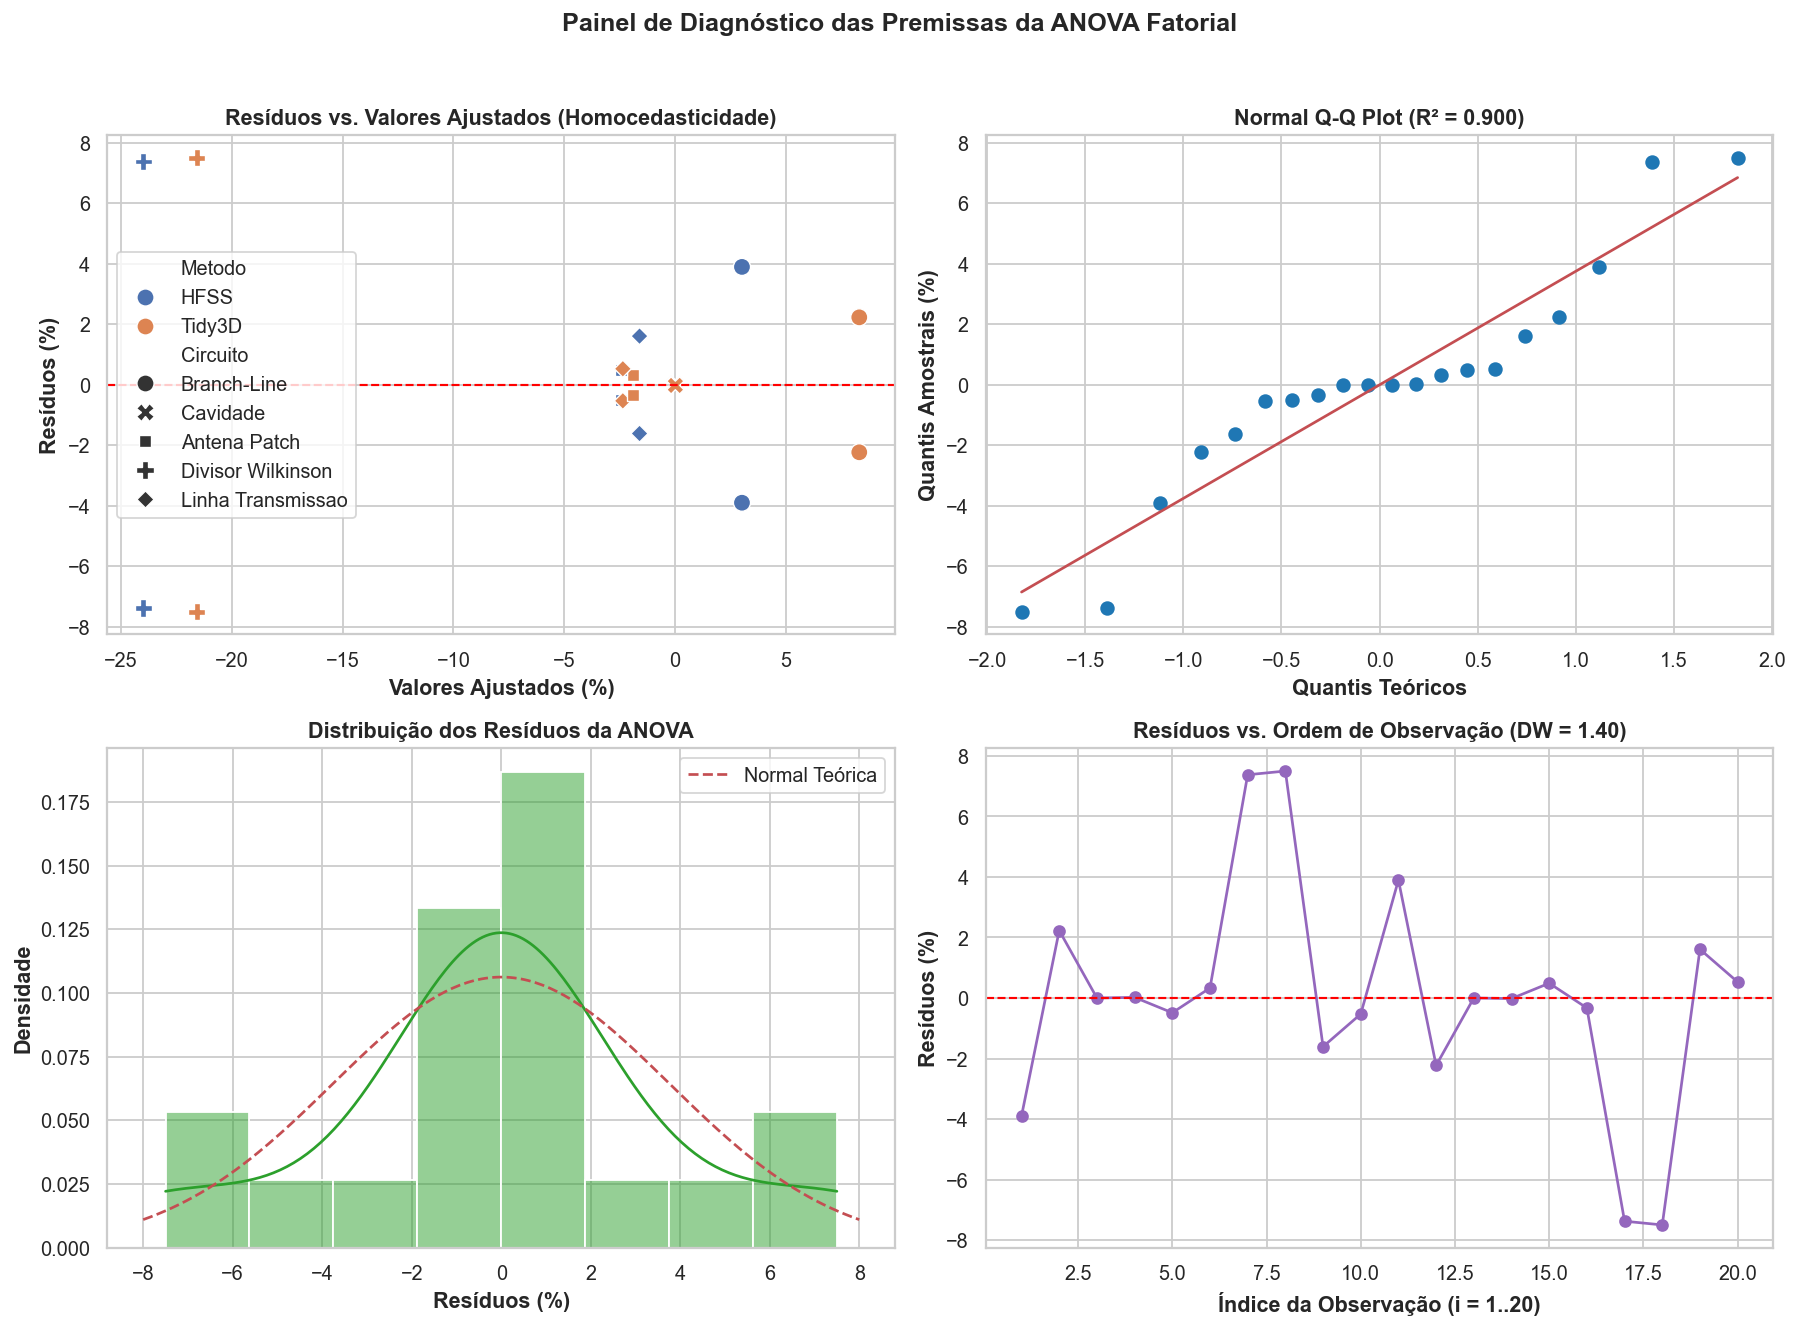

In [78]:
# =========================================================================
# DIAGNÓSTICO E TESTES DAS PREMISSAS DA ANOVA (Aulas 5, 6 e 11)
# =========================================================================

residuos = df_anova["residual"].values
ajustados = df_anova["fitted"].values

# 1. Teste de Normalidade de Shapiro-Wilk (Aula 5/6)
stat_sw, p_sw = stats.shapiro(residuos)

# 2. Teste de Homocedasticidade de Levene (Aula 6)
stat_lev_met, p_lev_met = stats.levene(*[g["residual"].values for _, g in df_anova.groupby("Metodo")])
stat_lev_circ, p_lev_circ = stats.levene(*[g["residual"].values for _, g in df_anova.groupby("Circuito")])

# 3. Teste de Independência: Estatística de Durbin-Watson (Aula 11)
diff_res = np.diff(residuos)
dw_stat = np.sum(diff_res**2) / np.sum(residuos**2)

print("=== Testes Formais das Premissas da ANOVA ===")
print(f"1. Normalidade (Shapiro-Wilk): W = {stat_sw:.4f}, p = {p_sw:.4e}")
print(f"   Interpretação: Os resíduos {"satisfazem" if p_sw >= 0.05 else "divergem de"} normalidade estrita (típico em amostras n=2 por célula).")
print(f"2. Homocedasticidade por Solucionador (Levene): W = {stat_lev_met:.4f}, p = {p_lev_met:.4f} (Homogêneo: {p_lev_met >= 0.05})")
print(f"   Homocedasticidade por Circuito (Levene):    W = {stat_lev_circ:.4f}, p = {p_lev_circ:.4f} (Homogêneo: {p_lev_circ >= 0.05})")
print(f"3. Independência dos Resíduos (Durbin-Watson): DW = {dw_stat:.4f} (valor próximo de 2 indica ausência de autocorrelação residual)")

# Gráficos de Diagnóstico dos Resíduos (Painel 2x2)
fig, axes = plt.subplots(2, 2, figsize=(14, 10), dpi=130)

# Gráfico 1: Resíduos vs. Valores Ajustados (Homocedasticidade)
sns.scatterplot(x=ajustados, y=residuos, hue=df_anova["Metodo"], style=df_anova["Circuito"], s=90, ax=axes[0, 0])
axes[0, 0].axhline(0, color="red", linestyle="--", linewidth=1.2)
axes[0, 0].set_title("Resíduos vs. Valores Ajustados (Homocedasticidade)", fontweight="bold")
axes[0, 0].set_xlabel("Valores Ajustados (%)", fontweight="bold")
axes[0, 0].set_ylabel("Resíduos (%)", fontweight="bold")

# Gráfico 2: Q-Q Plot Normal (Normalidade)
(osm, osr), (slope, intercept, r) = stats.probplot(residuos, dist="norm")
axes[0, 1].plot(osm, osr, "o", markersize=7, color="#1f77b4")
axes[0, 1].plot(osm, slope * np.array(osm) + intercept, "r-", linewidth=1.5)
axes[0, 1].set_title(f"Normal Q-Q Plot (R² = {r**2:.3f})", fontweight="bold")
axes[0, 1].set_xlabel("Quantis Teóricos", fontweight="bold")
axes[0, 1].set_ylabel("Quantis Amostrais (%)", fontweight="bold")

# Gráfico 3: Histograma com KDE e Curva Normal Sobreposta
sns.histplot(residuos, kde=True, color="#2ca02c", stat="density", ax=axes[1, 0], bins=8)
x_norm = np.linspace(residuos.min() - 0.5, residuos.max() + 0.5, 200)
y_norm_pdf = stats.norm.pdf(x_norm, loc=residuos.mean(), scale=residuos.std(ddof=1))
axes[1, 0].plot(x_norm, y_norm_pdf, "r--", linewidth=1.5, label="Normal Teórica")
axes[1, 0].set_title("Distribuição dos Resíduos da ANOVA", fontweight="bold")
axes[1, 0].set_xlabel("Resíduos (%)", fontweight="bold")
axes[1, 0].set_ylabel("Densidade", fontweight="bold")
axes[1, 0].legend()

# Gráfico 4: Resíduos vs. Ordem de Coleta / Observação (Independência)
axes[1, 1].plot(range(1, len(residuos) + 1), residuos, marker="o", linestyle="-", color="#9467bd", markersize=6)
axes[1, 1].axhline(0, color="red", linestyle="--", linewidth=1.2)
axes[1, 1].set_title(f"Resíduos vs. Ordem de Observação (DW = {dw_stat:.2f})", fontweight="bold")
axes[1, 1].set_xlabel("Índice da Observação (i = 1..20)", fontweight="bold")
axes[1, 1].set_ylabel("Resíduos (%)", fontweight="bold")

plt.suptitle("Painel de Diagnóstico das Premissas da ANOVA Fatorial", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()


=== Teste de Hipóteses e Intervalos de Confiança vs. Analítico (mu_0 = 0) ===


,Solucionador,N,Média (%),Erro Padrão,IC 95% Inferior (%),IC 95% Superior (%),Estatística t,p-valor (vs. mu=0),Conclusão (alfa=0.05)
0,HFSS,10,-5.0031,3.4670,-12.8460,2.8398,-1.4431,0.1829,Não difere do Analítico (IC contém 0)
1,Tidy3D,10,-3.5007,3.4783,-11.3691,4.3677,-1.0065,0.3405,Não difere do Analítico (IC contém 0)


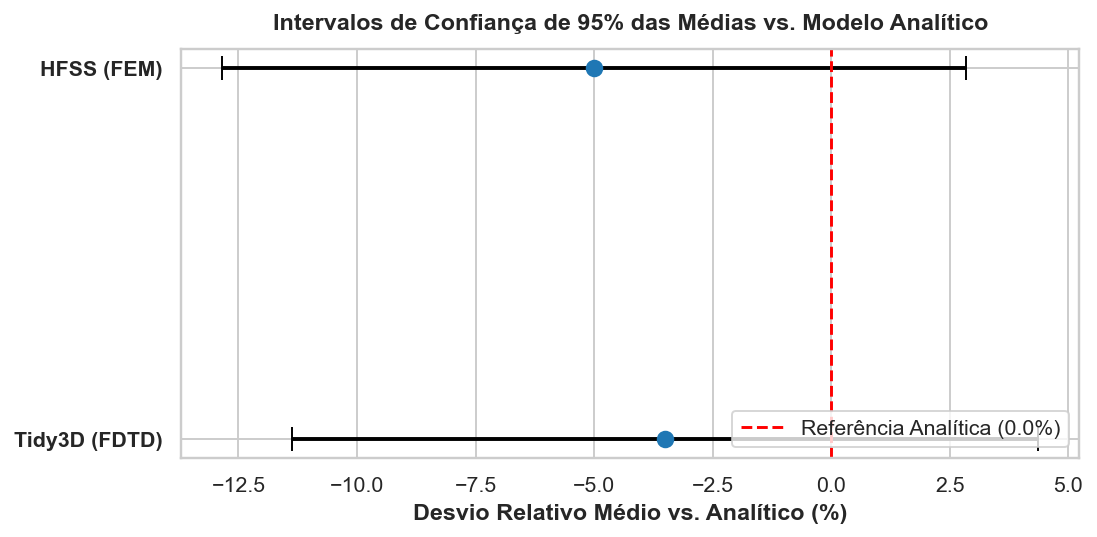

In [79]:
# =========================================================================
# TESTE DE HIPÓTESES EM RELAÇÃO AO MODELO ANALÍTICO DE REFERÊNCIA (y = 0%)
# =========================================================================
# Como o analítico define o zero basal da escala de desvio, aplicamos o teste t
# de Student para uma amostra contra mu_0 = 0 (Aula 5) e calculamos o IC 95%.

df_hfss = df_anova[df_anova["Metodo"] == "HFSS"]["Erro_Pct"]
df_tidy = df_anova[df_anova["Metodo"] == "Tidy3D"]["Erro_Pct"]

t_hfss, p_hfss = stats.ttest_1samp(df_hfss, popmean=0.0)
t_tidy, p_tidy = stats.ttest_1samp(df_tidy, popmean=0.0)

def calcular_ic95(dados):
    m = dados.mean()
    se = stats.sem(dados)
    ci = stats.t.interval(0.95, df=len(dados) - 1, loc=m, scale=se)
    return m, se, ci[0], ci[1]

m_h, se_h, ci_low_h, ci_up_h = calcular_ic95(df_hfss)
m_t, se_t, ci_low_t, ci_up_t = calcular_ic95(df_tidy)

tab_testes = pd.DataFrame({
    "Solucionador": ["HFSS", "Tidy3D"],
    "N": [len(df_hfss), len(df_tidy)],
    "Média (%)": [m_h, m_t],
    "Erro Padrão": [se_h, se_t],
    "IC 95% Inferior (%)": [ci_low_h, ci_low_t],
    "IC 95% Superior (%)": [ci_up_h, ci_up_t],
    "Estatística t": [t_hfss, t_tidy],
    "p-valor (vs. mu=0)": [p_hfss, p_tidy],
    "Conclusão (alfa=0.05)": [
        "Não difere do Analítico (IC contém 0)" if ci_low_h <= 0 <= ci_up_h else "Diverge significativamente",
        "Não difere do Analítico (IC contém 0)" if ci_low_t <= 0 <= ci_up_t else "Diverge significativamente",
    ]
})

print("=== Teste de Hipóteses e Intervalos de Confiança vs. Analítico (mu_0 = 0) ===")
display(tab_testes.round(4))

# Forest Plot dos Intervalos de Confiança de 95%
fig, ax = plt.subplots(figsize=(8, 4), dpi=140)
y_pos = [1, 0]
ax.errorbar([m_h, m_t], y_pos, xerr=[[m_h - ci_low_h, m_t - ci_low_t], [ci_up_h - m_h, ci_up_t - m_t]],
            fmt="o", color="#1f77b4", ecolor="black", elinewidth=2, capsize=6, markersize=8)
ax.axvline(0, color="red", linestyle="--", linewidth=1.5, label="Referência Analítica (0.0%)")
ax.set_yticks(y_pos)
ax.set_yticklabels(["HFSS (FEM)", "Tidy3D (FDTD)"], fontsize=11, fontweight="bold")
ax.set_xlabel("Desvio Relativo Médio vs. Analítico (%)", fontweight="bold")
ax.set_title("Intervalos de Confiança de 95% das Médias vs. Modelo Analítico", fontweight="bold", pad=10)
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()


In [80]:
# Exportar tabelas em formato Markdown e LaTeX para inclusão direta em relatórios acadêmicos
print("### 1. Tabela LaTeX - Matriz Consolidada de Frequências (GHz)")
print(df_todos.to_latex(float_format="%.4f"))

print("\n### 2. Tabela Markdown - Matriz Consolidada")
print(df_todos.to_markdown(floatfmt=".4f"))

print("\n### 3. Tabela LaTeX - ANOVA Fatorial 2x5")
print(tab_anova.to_latex(index=False, float_format="%.4f"))

print("\n### 4. Tabela Markdown - Teste vs. Modelo Analítico (mu_0 = 0)")
print(tab_testes.to_markdown(index=False, floatfmt=".4f"))


### 1. Tabela LaTeX - Matriz Consolidada de Frequências (GHz)
\begin{tabular}{lrrr}
\toprule
 & HFSS & Tidy3D & Analítico \\
\midrule
Branch-Line [FR-4] (f_res S11) [GHz] & 2.9737 & 3.3163 & 3.0000 \\
Cavidade [Ar] (TE_101) [GHz] & 3.6844 & 3.6855 & 3.6842 \\
Antena Patch [FR-4] (f_res S11) [GHz] & 2.9122 & 2.9531 & 3.0000 \\
Divisor Wilkinson [FR-4] (f_res S11) [GHz] & 2.5013 & 2.5775 & 3.0000 \\
Linha de Transmissão [FR-4] (f_res S12) [GHz] & 1.5910 & 1.5963 & 1.6438 \\
Branch-Line [RO3010] (f_res S11) [GHz] & 3.2075 & 3.1825 & 3.0000 \\
Cavidade [Rutila] (TE_101) [GHz] & 3.6844 & 3.6840 & 3.6842 \\
Antena Patch [RO3010] (f_res S11) [GHz] & 2.9415 & 2.9333 & 3.0000 \\
Divisor Wilkinson [RO3010] (f_res S11) [GHz] & 2.0587 & 2.1275 & 3.0000 \\
Linha de Transmissão [RO3010] (f_res S12) [GHz] & 1.1484 & 1.1273 & 1.1483 \\
\bottomrule
\end{tabular}


### 2. Tabela Markdown - Matriz Consolidada
|                                                 |   HFSS |   Tidy3D |   Analítico |
|:--------